# 11 · AI Frameworks: PyTorch and TensorFlow Side by Side

Almost all modern AI research and production runs on two Python frameworks: **PyTorch** (Meta, now the
PyTorch Foundation) and **TensorFlow** with its high-level API **Keras** (Google). Both do the same three
things: tensors on CPU or GPU, automatic differentiation, and building and training neural networks.
This module solves one problem in both, line by line, so the differences are visible.

> Our free course *Neural Networks 1001* builds these ideas from first principles; here the focus is the
> frameworks themselves.

**You will learn**
1. Tensors and automatic differentiation in each framework
2. The same model trained in both: PyTorch's explicit loop and Keras' `fit`
3. Comparing accuracy and speed fairly
4. Saving, loading and exporting models
5. How to choose, and the rest of the ecosystem (JAX, Hugging Face, ONNX)

## 1. Tensors and gradients
Both frameworks record operations on tensors and can differentiate through them. Check: the derivative
of $f(x) = x^3 + 2x$ at $x = 2$ is $3 \cdot 2^2 + 2 = 14$.

In [1]:
import os, time
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")       # quieter TensorFlow start-up
import numpy as np
import torch
import tensorflow as tf

print("PyTorch", torch.__version__, "| TensorFlow", tf.__version__)

x_pt = torch.tensor(2.0, requires_grad=True)
f_pt = x_pt ** 3 + 2 * x_pt
f_pt.backward()                                            # PyTorch: gradients accumulate in .grad
print("PyTorch    df/dx =", x_pt.grad.item())

x_tf = tf.Variable(2.0)
with tf.GradientTape() as tape:                             # TensorFlow: record inside a tape
    f_tf = x_tf ** 3 + 2 * x_tf
print("TensorFlow df/dx =", tape.gradient(f_tf, x_tf).numpy())

a = np.arange(6, dtype=np.float32).reshape(2, 3)
print(torch.from_numpy(a) @ torch.ones(3), tf.linalg.matvec(tf.constant(a), tf.ones(3)).numpy())

I0000 00:00:1792279602.488395  822786 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792279606.537984  822786 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


PyTorch 2.14.1+cpu | TensorFlow 2.21.0
PyTorch    df/dx = 14.0
TensorFlow df/dx = 14.0
tensor([ 3., 12.]) [ 3. 12.]


## 2. The task
Handwritten digits (8×8 pixels, 1,797 images, bundled with scikit-learn), split once so both frameworks
see exactly the same training and test images.

(1347, 8, 8) (450, 8, 8)


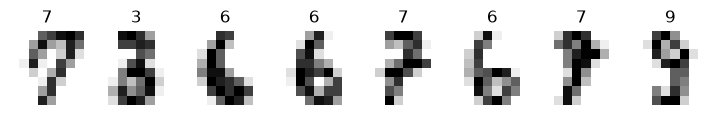

In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

digits = load_digits()
X = (digits.images / 16.0).astype(np.float32)               # scale pixels to [0, 1]
y = digits.target.astype(np.int64)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
print(X_train.shape, X_test.shape)

fig, axes = plt.subplots(1, 8, figsize=(9, 1.4))
for ax, img, label in zip(axes, X_train, y_train):
    ax.imshow(img, cmap="gray_r"); ax.set_title(label); ax.axis("off")
plt.show()

## 3. PyTorch: define a module, write the loop
PyTorch makes the training loop explicit. More code, but every step is visible and easy to customise,
which is one reason it dominates research.

In [3]:
torch.manual_seed(0)
EPOCHS, BATCH, LR = 30, 64, 1e-3

class SmallCNN(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.features = torch.nn.Sequential(
            torch.nn.Conv2d(1, 16, 3, padding=1), torch.nn.ReLU(), torch.nn.MaxPool2d(2),   # 8x8 -> 4x4
            torch.nn.Conv2d(16, 32, 3, padding=1), torch.nn.ReLU(),
        )
        self.head = torch.nn.Sequential(torch.nn.Flatten(), torch.nn.Linear(32 * 4 * 4, 64), torch.nn.ReLU(),
                                        torch.nn.Dropout(0.2), torch.nn.Linear(64, 10))
    def forward(self, x):
        return self.head(self.features(x))

pt_model = SmallCNN()
optimizer = torch.optim.Adam(pt_model.parameters(), lr=LR)
loss_fn = torch.nn.CrossEntropyLoss()
Xtr, ytr = torch.from_numpy(X_train[:, None]), torch.from_numpy(y_train)      # (N, 1, 8, 8): channels first
Xte, yte = torch.from_numpy(X_test[:, None]), torch.from_numpy(y_test)
loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(Xtr, ytr), batch_size=BATCH, shuffle=True)

pt_history, t0 = [], time.perf_counter()
for epoch in range(EPOCHS):
    pt_model.train()
    for xb, yb in loader:
        optimizer.zero_grad()                 # 1. reset gradients
        loss = loss_fn(pt_model(xb), yb)      # 2. forward pass
        loss.backward()                       # 3. backpropagate
        optimizer.step()                      # 4. update weights
    pt_model.eval()
    with torch.no_grad():
        pt_history.append((pt_model(Xte).argmax(1) == yte).float().mean().item())
pt_time = time.perf_counter() - t0
print(f"PyTorch: test accuracy {pt_history[-1]:.3f} after {EPOCHS} epochs, {pt_time:.1f} s, "
      f"{sum(p.numel() for p in pt_model.parameters()):,} parameters")

PyTorch: test accuracy 0.971 after 30 epochs, 4.7 s, 38,282 parameters


## 4. TensorFlow / Keras: declare the model, call `fit`
The same architecture. Keras hides the loop behind `compile` and `fit`, which is concise and hard to get
wrong. (Writing a custom loop with `GradientTape` is also possible when you need it.)

In [4]:
tf.keras.utils.set_random_seed(0)
tf_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(8, 8, 1)),                                   # channels last
    tf.keras.layers.Conv2D(16, 3, padding="same", activation="relu"), tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.Flatten(), tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2), tf.keras.layers.Dense(10),
])
tf_model.compile(optimizer=tf.keras.optimizers.Adam(LR),
                 loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
t0 = time.perf_counter()
hist = tf_model.fit(X_train[..., None], y_train, validation_data=(X_test[..., None], y_test),
                    epochs=EPOCHS, batch_size=BATCH, verbose=0)
tf_time = time.perf_counter() - t0
tf_history = hist.history["val_accuracy"]
print(f"TensorFlow: test accuracy {tf_history[-1]:.3f} after {EPOCHS} epochs, {tf_time:.1f} s, "
      f"{tf_model.count_params():,} parameters")

TensorFlow: test accuracy 0.978 after 30 epochs, 11.3 s, 38,282 parameters


## 5. Comparing them
Same data, same architecture, same optimiser and number of parameters. Differences in the final accuracy
come from random initialisation and shuffling, not from the framework.

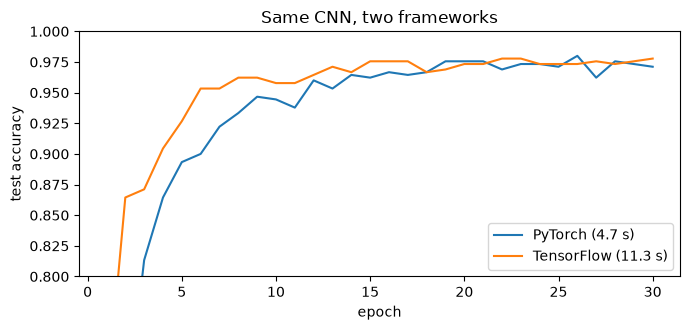

the two models agree on 97.8% of test images; both wrong on the same image: 7


In [5]:
plt.figure(figsize=(7, 3.4))
plt.plot(range(1, EPOCHS + 1), pt_history, label=f"PyTorch ({pt_time:.1f} s)")
plt.plot(range(1, EPOCHS + 1), tf_history, label=f"TensorFlow ({tf_time:.1f} s)")
plt.xlabel("epoch"); plt.ylabel("test accuracy"); plt.ylim(0.8, 1.0); plt.legend(); plt.title("Same CNN, two frameworks")
plt.tight_layout(); plt.show()

with torch.no_grad():
    p_pt = pt_model(Xte).argmax(1).numpy()
p_tf = tf_model.predict(X_test[..., None], verbose=0).argmax(1)
print(f"the two models agree on {np.mean(p_pt == p_tf):.1%} of test images; "
      f"both wrong on the same image: {np.sum((p_pt != y_test) & (p_tf != y_test))}")

## 6. Saving, loading, exporting

In [6]:
import tempfile
d = tempfile.mkdtemp()

torch.save(pt_model.state_dict(), os.path.join(d, "cnn.pt"))      # PyTorch: save the weights
restored = SmallCNN(); restored.load_state_dict(torch.load(os.path.join(d, "cnn.pt"))); restored.eval()
with torch.no_grad():
    print("PyTorch reload identical:", torch.equal(restored(Xte).argmax(1), pt_model(Xte).argmax(1)))

tf_model.save(os.path.join(d, "cnn.keras"))                         # Keras: architecture + weights in one file
reloaded = tf.keras.models.load_model(os.path.join(d, "cnn.keras"))
print("Keras reload identical:", np.array_equal(reloaded.predict(X_test[..., None], verbose=0).argmax(1), p_tf))

print({f: f"{os.path.getsize(os.path.join(d, f)) / 1024:.0f} KB" for f in os.listdir(d)})

PyTorch reload identical: True


Keras reload identical: True
{'cnn.pt': '153 KB', 'cnn.keras': '485 KB'}


For deployment, models are often exported to a framework-neutral or optimised format: **ONNX** (both
frameworks, run anywhere with ONNX Runtime), **TorchScript / torch.export** (PyTorch), **SavedModel** and
**LiteRT** (formerly TensorFlow Lite, for phones and microcontrollers).

## 7. Choosing
| | PyTorch | TensorFlow / Keras |
|---|---|---|
| style | explicit, Pythonic, eager by default | high-level `fit`, graph compilation with `tf.function` |
| strongest in | research, new architectures, most new papers and LLM work | production pipelines (TFX), mobile and embedded (LiteRT), TPUs |
| ecosystem | Hugging Face Transformers, PyTorch Lightning, torchvision | Keras, TensorFlow Serving, TF.js in the browser |
| note | | Keras 3 can also run on PyTorch or JAX as its backend |

The wider landscape: **JAX** (Google; NumPy API with composable transforms `grad`, `jit`, `vmap`, popular
for research at scale), **Hugging Face** (pretrained models and datasets for all frameworks),
**scikit-learn** (classical machine learning, often the right first model), **ONNX Runtime** (fast
inference anywhere).

## Exercises
1. Write the Keras model's training with a custom loop using `tf.GradientTape`, mirroring the PyTorch loop.
2. Remove the convolutional layers and use only dense layers. How much accuracy is lost?
3. Export the PyTorch model to ONNX (`torch.onnx.export`) and run it with `onnxruntime`.